# Linear model vs. decision tree: Bike Sharing

Step 6 of `01_bike_sharing_project.ipynb`, continuing `eda_short.ipynb` and `baseline_short.ipynb`. Two model families, each trained first with a few hand-picked settings and then tuned with a grid search:

1. **Linear model:** `Ridge` in a `Pipeline` with one-hot encoding and scaling.
2. **Decision tree:** `DecisionTreeRegressor` with only the preprocessing a tree needs.

Same split, same `prepare_data` and the **same 5 folds** as the baselines, so all scores are directly comparable. Main metric: **RMSE** (see `baseline_short.ipynb`), also MAE and R².

Every model is logged while it is trained: the scores of each fold and their mean (console and `logs/model_selection.log`). For the grid searches, every candidate is logged; the file also contains the fold scores of each candidate.

In [1]:
import logging
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils.validation import check_is_fitted

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

## 1. Data preparation (from `eda_short.ipynb`)

In [2]:
df = pd.read_csv("data/bike_sharing.csv", parse_dates=["datetime"])
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)  # df_test stays locked until step 8


def nth_sunday(year, month, n):
    """Date of the n-th Sunday of a month."""
    days = pd.date_range(f"{year}-{month:02d}-01", periods=31, freq="D")
    sundays = days[(days.month == month) & (days.dayofweek == 6)]
    return sundays[n - 1]


def dst_artifact_hours(data):
    """Boolean mask of the hours that are corrupt because of the clock change."""
    years = data["datetime"].dt.year.unique()
    spring_forward = [nth_sunday(y, 3, 2) + pd.Timedelta(hours=2) for y in years]  # 02:00 does not exist
    fall_back = [nth_sunday(y, 11, 1) + pd.Timedelta(hours=1) for y in years]      # 01:00 counts two hours
    return data["datetime"].isin(spring_forward + fall_back)


def remove_dst_artifacts(data):
    """Drop the non-existent 02:00 on spring-forward Sundays and the doubled 01:00 on fall-back Sundays."""
    return data[~dst_artifact_hours(data)].copy()


WEATHER_GROUPS = {
    0: "clear", 1: "clear", 2: "clear",
    3: "overcast",
    51: "drizzle", 53: "drizzle", 55: "drizzle",
    61: "rain", 63: "rain", 65: "rain",
    71: "snow", 73: "snow", 75: "snow",
}


def add_features(data):
    """Derive calendar features from `datetime` and `holiday`, and group the weather codes."""
    data = data.copy()
    data["hour"] = data["datetime"].dt.hour
    data["weekday"] = data["datetime"].dt.dayofweek  # 0 = Monday, 6 = Sunday
    data["month"] = data["datetime"].dt.month
    data["is_holiday"] = data["holiday"].notna().astype(int)
    data["day_type"] = np.select(
        [data["is_holiday"] == 1, data["weekday"] >= 5],
        ["holiday", "weekend"],
        default="working day",
    )
    data["weather_group"] = data["weather_code"].map(WEATHER_GROUPS)
    return data


LEAKAGE_COLUMNS = ["casual", "member"]


def prepare_data(data):
    """All manual changes to the raw data. Apply it unchanged to df_test in step 8."""
    data = remove_dst_artifacts(data)
    data = add_features(data)
    return data.drop(columns=LEAKAGE_COLUMNS + ["holiday"])


TARGET = "rentals"
df_train_prepared = prepare_data(df_train)
X_train = df_train_prepared.drop(columns=[TARGET, "datetime"])
y_train = df_train_prepared[TARGET]
print("X_train:", X_train.shape, "| y_train:", y_train.shape)

X_train: (14013, 14) | y_train: (14013,)


## 2. Cross-validation and logging

- `cv_scores` trains a model on the 5 folds, **logs the scores of every fold** and their mean, and returns the means as one table row (same columns as in `baseline_short.ipynb`, plus the spread over the folds and the fit time).
- `log_search` logs **every candidate** of a grid search (mean scores in the console, fold scores in the log file) and returns all candidates as a table, best first.

In [3]:
LOG_FILE = Path("logs/model_selection.log")
LOG_FILE.parent.mkdir(exist_ok=True)

logger = logging.getLogger("model_selection")
logger.setLevel(logging.DEBUG)
logger.propagate = False
logger.handlers.clear()  # no duplicated lines when the cell is run again

console_handler = logging.StreamHandler(sys.stdout)
console_handler.setLevel(logging.INFO)
console_handler.setFormatter(logging.Formatter("%(asctime)s | %(message)s", datefmt="%H:%M:%S"))
file_handler = logging.FileHandler(LOG_FILE, mode="w")  # DEBUG: also the fold scores of every search candidate
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)-5s | %(message)s"))
logger.addHandler(console_handler)
logger.addHandler(file_handler)

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)  # same folds as the baselines
SCORING = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}


def error(scores):
    """sklearn returns negated errors: flip the sign back (0.0 - x also avoids printing -0.0)."""
    return 0.0 - np.asarray(scores)


def cv_scores(model, name, X=X_train, y=y_train):
    """Cross-validate a model, log the scores of every fold and return the mean scores as one table row."""
    res = cross_validate(model, X, y, cv=cv, scoring=SCORING, return_train_score=True)
    logger.info("--- %s ---", name)
    for fold in range(cv.get_n_splits()):
        logger.info(
            "fold %d | train RMSE %6.1f | val RMSE %6.1f | val MAE %6.1f | val R2 %.3f | fit %.2f s",
            fold + 1, error(res["train_RMSE"][fold]), error(res["test_RMSE"][fold]), error(res["test_MAE"][fold]),
            res["test_R2"][fold], res["fit_time"][fold],
        )
    row = {}
    for metric in SCORING:
        flip = np.asarray if metric == "R2" else error
        row[f"train_{metric}"] = flip(res[f"train_{metric}"]).mean()
        row[f"cv_{metric}"] = flip(res[f"test_{metric}"]).mean()
    row["cv_RMSE_std"] = res["test_RMSE"].std()
    row["fit_time_s"] = res["fit_time"].mean()
    logger.info(
        "mean   | train RMSE %6.1f | val RMSE %6.1f ± %.1f | val MAE %6.1f | val R2 %.3f",
        row["train_RMSE"], row["cv_RMSE"], row["cv_RMSE_std"], row["cv_MAE"], row["cv_R2"],
    )
    return pd.Series(row, name=name)


def label(value):
    """Short readable label of a hyperparameter value, for logs and tables."""
    if value is None:
        return "none"
    if isinstance(value, FunctionTransformer):
        return value.func.__name__
    if isinstance(value, BaseEstimator):
        return type(value).__name__
    return value


PARAM_NAMES = {"transformer": "target"}  # TransformedTargetRegressor(transformer=...) transforms the target


def short_params(params):
    """{'prep__hour': OneHotEncoder(...), ...} -> {'hour': 'OneHotEncoder', ...}"""
    short = {}
    for key, value in params.items():
        name = key.split("__")[-1]
        short[PARAM_NAMES.get(name, name)] = label(value)
    return short


def log_search(search, name):
    """Log every candidate of a fitted grid search and return all candidates as a table, best first."""
    res = search.cv_results_
    n_candidates, n_folds = len(res["params"]), search.n_splits_
    logger.info("=== %s: %d candidates x %d folds = %d fits ===", name, n_candidates, n_folds, n_candidates * n_folds)
    rows = []
    for i, params in enumerate(res["params"]):
        params = short_params(params)
        param_text = ", ".join(f"{k}={v}" for k, v in params.items())
        logger.info(
            "#%02d | %s | train RMSE %6.1f | val RMSE %6.1f ± %5.1f | val R2 %.3f",
            i + 1, param_text, error(res["mean_train_RMSE"][i]), error(res["mean_test_RMSE"][i]),
            res["std_test_RMSE"][i], res["mean_test_R2"][i],
        )
        fold_rmse = [error(res[f"split{f}_test_RMSE"][i]) for f in range(n_folds)]
        logger.debug("#%02d | val RMSE per fold: %s", i + 1, ", ".join(f"{s:.1f}" for s in fold_rmse))
        rows.append({
            **params,
            "train_RMSE": error(res["mean_train_RMSE"][i]),
            "cv_RMSE": error(res["mean_test_RMSE"][i]),
            "cv_RMSE_std": res["std_test_RMSE"][i],
            "cv_MAE": error(res["mean_test_MAE"][i]),
            "cv_R2": res["mean_test_R2"][i],
            "rank": res["rank_test_RMSE"][i],
        })
    logger.info("BEST %s | %s | val RMSE %.1f", name, short_params(search.best_params_), error(search.best_score_))
    return pd.DataFrame(rows).sort_values("rank").set_index("rank")

### Baselines (from `baseline_short.ipynb`)

Recomputed with the same folds, as reference rows for the final table.

In [5]:
class GroupMeanRegressor(RegressorMixin, BaseEstimator):
    """Rule-based baseline: predict the mean target of the training rows that share the same value of `feature`."""

    def __init__(self, feature="hour"):
        self.feature = feature

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.means_ = y.groupby(X[self.feature]).mean()
        self.global_mean_ = y.mean()  # fallback for values not seen in training
        return self

    def predict(self, X):
        check_is_fitted(self, "means_")
        return X[self.feature].map(self.means_).fillna(self.global_mean_).to_numpy()


baseline_scores = pd.DataFrame([
    cv_scores(DummyRegressor(strategy="mean"), "Mean baseline"),
    cv_scores(GroupMeanRegressor(feature="hour"), "Rule baseline (mean per hour)"),
])

14:14:07 | --- Mean baseline ---
14:14:07 | fold 1 | train RMSE  632.4 | val RMSE  651.3 | val MAE  535.3 | val R2 -0.000 | fit 0.09 s
14:14:07 | fold 2 | train RMSE  633.4 | val RMSE  647.6 | val MAE  527.1 | val R2 -0.001 | fit 0.00 s
14:14:07 | fold 3 | train RMSE  640.7 | val RMSE  618.3 | val MAE  512.3 | val R2 -0.002 | fit 0.04 s
14:14:07 | fold 4 | train RMSE  636.9 | val RMSE  633.6 | val MAE  517.9 | val R2 -0.001 | fit 0.02 s
14:14:07 | fold 5 | train RMSE  637.7 | val RMSE  630.4 | val MAE  517.7 | val R2 -0.001 | fit 0.03 s
14:14:07 | mean   | train RMSE  636.2 | val RMSE  636.2 ± 12.0 | val MAE  522.1 | val R2 -0.001
14:14:07 | --- Rule baseline (mean per hour) ---
14:14:07 | fold 1 | train RMSE  392.3 | val RMSE  399.9 | val MAE  283.1 | val R2 0.623 | fit 0.07 s
14:14:07 | fold 2 | train RMSE  394.9 | val RMSE  390.1 | val MAE  275.5 | val R2 0.637 | fit 0.02 s
14:14:07 | fold 3 | train RMSE  395.9 | val RMSE  385.2 | val MAE  272.4 | val R2 0.611 | fit 0.01 s
14:14:07 

## 3. Linear model: `Ridge`

### 3.1 Preprocessing

A linear model adds up one weight per input column, so the inputs have to be shaped for it:

| Feature | Treatment | Why |
|:--|:--|:--|
| `hour` | one-hot (**tuned:** one-hot vs. scaled number) | Two commuter peaks: rentals are not a straight line in the hour |
| `hour` × `day_type` | one-hot of the combined column (**tuned:** on/off) | Different daily patterns on working days and weekends (EDA iteration 4) |
| `weekday`, `month`, `day_type`, `weather_group` | one-hot | Categories or non-linear effects (season) |
| `temperature`, `humidity`, `precipitation`, `snowfall`, `wind_speed`, `cloud_cover` | `StandardScaler` | The Ridge penalty treats all weights alike, so the columns need the same scale |
| `feels_like`, `weather_code`, `is_holiday` | dropped | Duplicate `temperature` (ρ = 0.99), `weather_group` and `day_type` |
| target `rentals` | raw or `log1p` (**tuned**) | Right-skewed; on the log scale, the effects of hour, season and weather multiply instead of adding up |

In [6]:
CAT_LINEAR = ["weekday", "month", "day_type", "weather_group"]
NUM_LINEAR = ["temperature", "humidity", "precipitation", "snowfall", "wind_speed", "cloud_cover"]
LOG_TARGET = FunctionTransformer(np.log1p, inverse_func=np.expm1)  # predictions are transformed back to rentals


def add_hour_day_type(X):
    """Combine `hour` and `day_type` into one column, so that a linear model can learn one daily pattern per day type."""
    return X.assign(hour_day_type=X["day_type"] + "_" + X["hour"].astype(str))


def onehot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def make_linear_model(hour_onehot=True, interaction=False, log_target=False, alpha=1.0):
    """Ridge pipeline. The arguments are the options compared in the tuning (3.3)."""
    return Pipeline([
        ("features", FunctionTransformer(add_hour_day_type)),
        ("prep", ColumnTransformer([
            ("hour", onehot() if hour_onehot else StandardScaler(), ["hour"]),
            ("interaction", onehot() if interaction else "drop", ["hour_day_type"]),
            ("cat", onehot(), CAT_LINEAR),
            ("num", StandardScaler(), NUM_LINEAR),
        ])),  # all other columns are dropped
        ("model", TransformedTargetRegressor(regressor=Ridge(alpha=alpha), transformer=LOG_TARGET if log_target else None)),
    ])


make_linear_model(interaction=True, log_target=True)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...t 0x114af1580>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary 

### 3.2 First models

One step at a time, each with the default `alpha = 1`, to see what each part of the preprocessing gains.

In [7]:
linear_scores = pd.DataFrame([
    cv_scores(make_linear_model(hour_onehot=False), "Ridge: hour as number"),
    cv_scores(make_linear_model(), "Ridge: hour one-hot"),
    cv_scores(make_linear_model(interaction=True), "Ridge: + hour x day_type"),
    cv_scores(make_linear_model(interaction=True, log_target=True), "Ridge: + log target"),
])
linear_scores.round(3)

14:14:09 | --- Ridge: hour as number ---
14:14:09 | fold 1 | train RMSE  447.7 | val RMSE  459.8 | val MAE  351.6 | val R2 0.501 | fit 0.17 s
14:14:09 | fold 2 | train RMSE  448.5 | val RMSE  456.4 | val MAE  355.9 | val R2 0.503 | fit 0.10 s
14:14:09 | fold 3 | train RMSE  452.8 | val RMSE  439.0 | val MAE  340.5 | val R2 0.495 | fit 0.11 s
14:14:09 | fold 4 | train RMSE  448.6 | val RMSE  456.0 | val MAE  351.1 | val R2 0.482 | fit 0.10 s
14:14:09 | fold 5 | train RMSE  451.6 | val RMSE  444.0 | val MAE  345.0 | val R2 0.504 | fit 0.11 s
14:14:09 | mean   | train RMSE  449.8 | val RMSE  451.0 ± 8.1 | val MAE  348.8 | val R2 0.497
14:14:10 | --- Ridge: hour one-hot ---
14:14:10 | fold 1 | train RMSE  306.5 | val RMSE  307.7 | val MAE  232.3 | val R2 0.777 | fit 0.10 s
14:14:10 | fold 2 | train RMSE  307.1 | val RMSE  305.8 | val MAE  234.5 | val R2 0.777 | fit 0.08 s
14:14:10 | fold 3 | train RMSE  308.3 | val RMSE  299.9 | val MAE  227.2 | val R2 0.764 | fit 0.07 s
14:14:10 | fold 4 

,train_RMSE,cv_RMSE,train_MAE,cv_MAE,train_R2,cv_R2,cv_RMSE_std,fit_time_s
Ridge: hour as number,449.839,451.049,347.817,348.820,0.500,0.497,8.054,0.119
Ridge: hour one-hot,306.274,308.321,232.537,233.959,0.768,0.765,5.740,0.080
Ridge: + hour x day_type,245.214,247.844,180.776,182.573,0.851,0.848,8.139,0.162
Ridge: + log target,243.249,245.721,153.728,155.227,0.854,0.850,13.608,0.121


### 3.3 Tuning with `GridSearchCV`

All combinations of the three preprocessing options and the regularisation strength `alpha`: 2 × 2 × 2 × 5 = 40 candidates, each scored on the same 5 folds. The best candidate (lowest CV RMSE) is refitted on the whole training set.

In [8]:
linear_grid = {
    "prep__hour": [StandardScaler(), onehot()],
    "prep__interaction": ["drop", onehot()],
    "model__transformer": [None, LOG_TARGET],
    "model__regressor__alpha": [0.01, 0.1, 1, 10, 100],
}
linear_search = GridSearchCV(
    make_linear_model(), linear_grid, cv=cv, scoring=SCORING, refit="RMSE", return_train_score=True, n_jobs=-1,
)
linear_search.fit(X_train, y_train)
linear_candidates = log_search(linear_search, "Ridge")
linear_candidates.head(10).round(3)

14:14:35 | === Ridge: 40 candidates x 5 folds = 200 fits ===
14:14:35 | #01 | alpha=0.01, target=none, hour=StandardScaler, interaction=drop | train RMSE  449.8 | val RMSE  451.1 ±   8.1 | val R2 0.497
14:14:35 | #02 | alpha=0.01, target=none, hour=StandardScaler, interaction=OneHotEncoder | train RMSE  245.2 | val RMSE  247.9 ±   8.2 | val R2 0.848
14:14:35 | #03 | alpha=0.01, target=none, hour=OneHotEncoder, interaction=drop | train RMSE  306.3 | val RMSE  308.3 ±   5.8 | val R2 0.765
14:14:35 | #04 | alpha=0.01, target=none, hour=OneHotEncoder, interaction=OneHotEncoder | train RMSE  245.2 | val RMSE  247.9 ±   8.2 | val R2 0.848
14:14:35 | #05 | alpha=0.01, target=log1p, hour=StandardScaler, interaction=drop | train RMSE  537.9 | val RMSE  539.1 ±  10.5 | val R2 0.281
14:14:35 | #06 | alpha=0.01, target=log1p, hour=StandardScaler, interaction=OneHotEncoder | train RMSE  243.0 | val RMSE  245.5 ±  13.6 | val R2 0.850
14:14:35 | #07 | alpha=0.01, target=log1p, hour=OneHotEncoder, int

,alpha,target,hour,interaction,train_RMSE,cv_RMSE,cv_RMSE_std,cv_MAE,cv_R2
rank,,,,,,,,,
1,0.01,log1p,StandardScaler,OneHotEncoder,242.994,245.543,13.649,155.033,0.850
2,0.01,log1p,OneHotEncoder,OneHotEncoder,242.994,245.543,13.649,155.032,0.850
3,0.10,log1p,StandardScaler,OneHotEncoder,243.024,245.557,13.641,155.059,0.850
4,0.10,log1p,OneHotEncoder,OneHotEncoder,243.016,245.558,13.645,155.049,0.850
5,1.00,log1p,OneHotEncoder,OneHotEncoder,243.249,245.721,13.608,155.227,0.850
6,1.00,log1p,StandardScaler,OneHotEncoder,243.367,245.771,13.591,155.358,0.850
7,1.00,none,OneHotEncoder,OneHotEncoder,245.214,247.844,8.139,182.573,0.848
8,1.00,none,StandardScaler,OneHotEncoder,245.236,247.851,8.176,182.657,0.848
9,0.10,none,StandardScaler,OneHotEncoder,245.210,247.873,8.175,182.531,0.848


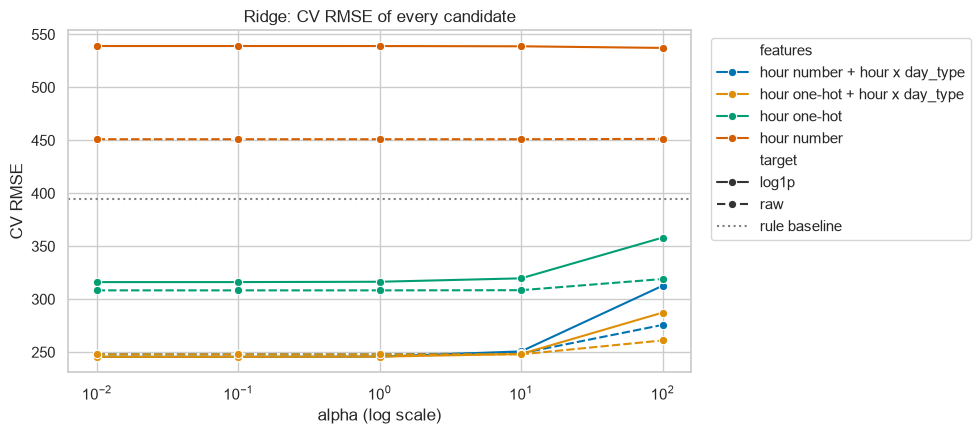

In [9]:
plot_data = linear_candidates.assign(
    features=lambda d: "hour " + d["hour"].map({"OneHotEncoder": "one-hot", "StandardScaler": "number"})
    + d["interaction"].map({"OneHotEncoder": " + hour x day_type", "drop": ""}),
    target=lambda d: d["target"].replace({"none": "raw"}),
)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=plot_data, x="alpha", y="cv_RMSE", hue="features", style="target", marker="o", ax=ax)
ax.axhline(baseline_scores.loc["Rule baseline (mean per hour)", "cv_RMSE"], color="grey", ls=":", label="rule baseline")
ax.set(xscale="log", title="Ridge: CV RMSE of every candidate", xlabel="alpha (log scale)", ylabel="CV RMSE")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [10]:
ridge_best = linear_search.best_estimator_  # refitted on the whole training set, kept for step 8
ridge_best_scores = cv_scores(ridge_best, "Ridge (tuned)")
print("Best parameters:", short_params(linear_search.best_params_))

14:14:36 | --- Ridge (tuned) ---
14:14:36 | fold 1 | train RMSE  246.8 | val RMSE  232.2 | val MAE  148.7 | val R2 0.873 | fit 0.10 s
14:14:36 | fold 2 | train RMSE  242.4 | val RMSE  253.9 | val MAE  159.7 | val R2 0.846 | fit 0.08 s
14:14:36 | fold 3 | train RMSE  244.1 | val RMSE  230.7 | val MAE  149.0 | val R2 0.861 | fit 0.08 s
14:14:36 | fold 4 | train RMSE  238.9 | val RMSE  267.0 | val MAE  165.7 | val R2 0.822 | fit 0.08 s
14:14:36 | fold 5 | train RMSE  242.9 | val RMSE  244.0 | val MAE  152.0 | val R2 0.850 | fit 0.07 s
14:14:36 | mean   | train RMSE  243.0 | val RMSE  245.5 ± 13.6 | val MAE  155.0 | val R2 0.850
Best parameters: {'alpha': 0.01, 'target': 'log1p', 'hour': 'StandardScaler', 'interaction': 'OneHotEncoder'}


**Findings (linear model):**
- **`hour` as a number** (CV RMSE ≈ 451) is *worse than the rule baseline* (≈ 395): a straight line cannot draw two commuter peaks. One-hot encoding gives every hour its own level → ≈ 308.
- **`hour` × `day_type`** is the largest single gain (≈ 248, −20 %): one daily pattern per day type, as found in EDA iteration 4.
- **Log target:** RMSE only a little lower (≈ 245.5 vs. 247.8), but MAE much lower (≈ 155 vs. 183). On the log scale, weather and season change the rentals of an hour *by a factor*, which fits the quiet hours far better. The spread over the folds grows (± 14 vs. ± 8): a small error on the log scale becomes a large one at the busy hours.
- With the interaction, the encoding of `hour` no longer matters (the interaction columns already contain the hour): ranks 1 and 2 are the same model, so `StandardScaler` only wins a tie.
- **`alpha`** has no effect up to 10 and makes the model worse at 100. With ≈ 14,000 rows and ≈ 130 columns, there is little to regularise: training ≈ CV RMSE (gap ≈ 2.5), so the linear model is limited by **bias** (what it can express), not by variance.

## 4. Decision tree: `DecisionTreeRegressor`

### 4.1 Preprocessing

A tree needs much less than the linear model:

- **No scaling:** a split is a threshold (`temperature <= 12.3`), and it stays the same when a column is scaled.
- **No one-hot encoding:** the tree cuts `hour` into intervals itself (e.g. 7 to 9), and it learns the `hour` × `day_type` interaction by splitting on one after the other.
- **No log target:** the splits of a tree are the same after any monotonic transformation of a feature; for the target, the `poisson` criterion is tuned instead, which suits counts.
- **Only the text columns** `day_type` and `weather_group` are turned into numbers (`OrdinalEncoder`, ordered by the size of their effect). All other columns are passed through; redundant columns such as `feels_like` do no harm.

In [11]:
CAT_TREE = ["day_type", "weather_group"]
CAT_ORDER = [["working day", "weekend", "holiday"], ["clear", "overcast", "drizzle", "rain", "snow"]]


def make_tree_model(**tree_params):
    """Decision tree pipeline: ordinal codes for the text columns, all other columns unchanged."""
    return Pipeline([
        ("prep", ColumnTransformer(
            [("cat", OrdinalEncoder(categories=CAT_ORDER, handle_unknown="use_encoded_value", unknown_value=-1), CAT_TREE)],
            remainder="passthrough",
        )),
        ("model", DecisionTreeRegressor(random_state=42, **tree_params)),
    ])


make_tree_model()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

### 4.2 First models

The default tree grows until every leaf is pure; two depth limits show how strongly that overfits.

In [12]:
tree_scores = pd.DataFrame([
    cv_scores(make_tree_model(), "Tree: no limits (default)"),
    cv_scores(make_tree_model(max_depth=5), "Tree: max_depth=5"),
    cv_scores(make_tree_model(max_depth=10), "Tree: max_depth=10"),
])
tree_scores.round(3)

14:14:37 | --- Tree: no limits (default) ---
14:14:37 | fold 1 | train RMSE    0.0 | val RMSE  236.5 | val MAE  143.2 | val R2 0.868 | fit 0.11 s
14:14:37 | fold 2 | train RMSE    0.0 | val RMSE  216.8 | val MAE  138.6 | val R2 0.888 | fit 0.09 s
14:14:37 | fold 3 | train RMSE    0.0 | val RMSE  231.3 | val MAE  145.7 | val R2 0.860 | fit 0.09 s
14:14:37 | fold 4 | train RMSE    0.0 | val RMSE  250.5 | val MAE  152.2 | val R2 0.844 | fit 0.09 s
14:14:37 | fold 5 | train RMSE    0.0 | val RMSE  248.4 | val MAE  147.7 | val R2 0.845 | fit 0.09 s
14:14:37 | mean   | train RMSE    0.0 | val RMSE  236.7 ± 12.2 | val MAE  145.5 | val R2 0.861
14:14:37 | --- Tree: max_depth=5 ---
14:14:37 | fold 1 | train RMSE  324.0 | val RMSE  328.1 | val MAE  216.0 | val R2 0.746 | fit 0.04 s
14:14:37 | fold 2 | train RMSE  325.2 | val RMSE  328.5 | val MAE  217.2 | val R2 0.742 | fit 0.04 s
14:14:37 | fold 3 | train RMSE  326.2 | val RMSE  322.8 | val MAE  214.6 | val R2 0.727 | fit 0.04 s
14:14:37 | fold

,train_RMSE,cv_RMSE,train_MAE,cv_MAE,train_R2,cv_R2,cv_RMSE_std,fit_time_s
Tree: no limits (default),0.000,236.713,0.000,145.472,1.000,0.861,12.248,0.095
Tree: max_depth=5,325.109,328.256,215.279,217.921,0.739,0.733,5.914,0.036
Tree: max_depth=10,182.858,222.830,110.256,139.486,0.917,0.877,9.188,0.056


### 4.3 Tuning with `GridSearchCV`

- `max_depth` and `min_samples_leaf` control the size of the tree (overfitting vs. underfitting);
- `criterion`: `squared_error` (mean of the leaf, minimises the squared error) vs. `poisson` (for counts, puts less weight on errors in hours with many rentals).

7 × 6 × 2 = 84 candidates.

In [13]:
tree_grid = {
    "model__max_depth": [6, 8, 10, 12, 15, 20, None],
    "model__min_samples_leaf": [1, 2, 5, 10, 20, 50],
    "model__criterion": ["squared_error", "poisson"],
}
tree_search = GridSearchCV(
    make_tree_model(), tree_grid, cv=cv, scoring=SCORING, refit="RMSE", return_train_score=True, n_jobs=-1,
)
tree_search.fit(X_train, y_train)
tree_candidates = log_search(tree_search, "Decision tree")
tree_candidates.head(10).round(3)

14:14:52 | === Decision tree: 84 candidates x 5 folds = 420 fits ===
14:14:52 | #01 | criterion=squared_error, max_depth=6, min_samples_leaf=1 | train RMSE  286.0 | val RMSE  291.3 ±   6.4 | val R2 0.790
14:14:52 | #02 | criterion=squared_error, max_depth=6, min_samples_leaf=2 | train RMSE  286.0 | val RMSE  291.3 ±   6.4 | val R2 0.790
14:14:52 | #03 | criterion=squared_error, max_depth=6, min_samples_leaf=5 | train RMSE  286.0 | val RMSE  291.3 ±   6.4 | val R2 0.790
14:14:52 | #04 | criterion=squared_error, max_depth=6, min_samples_leaf=10 | train RMSE  286.0 | val RMSE  291.3 ±   6.4 | val R2 0.790
14:14:52 | #05 | criterion=squared_error, max_depth=6, min_samples_leaf=20 | train RMSE  286.0 | val RMSE  291.2 ±   6.4 | val R2 0.790
14:14:52 | #06 | criterion=squared_error, max_depth=6, min_samples_leaf=50 | train RMSE  286.8 | val RMSE  291.9 ±   6.4 | val R2 0.789
14:14:52 | #07 | criterion=squared_error, max_depth=8, min_samples_leaf=1 | train RMSE  227.4 | val RMSE  242.3 ±   8.

,criterion,max_depth,min_samples_leaf,train_RMSE,cv_RMSE,cv_RMSE_std,cv_MAE,cv_R2
rank,,,,,,,,
1,poisson,20,10,155.035,203.592,9.044,127.802,0.897
2,poisson,15,10,157.649,203.610,9.334,128.003,0.897
3,poisson,none,10,155.002,203.707,9.157,127.853,0.897
4,poisson,12,10,167.279,204.745,9.415,129.154,0.896
5,poisson,12,5,154.844,205.350,10.558,128.864,0.895
6,poisson,15,5,132.225,205.778,11.149,128.332,0.895
7,squared_error,20,10,156.628,206.331,10.801,129.704,0.894
8,squared_error,none,10,156.617,206.382,10.796,129.725,0.894
9,squared_error,15,10,158.410,206.517,10.970,129.843,0.894


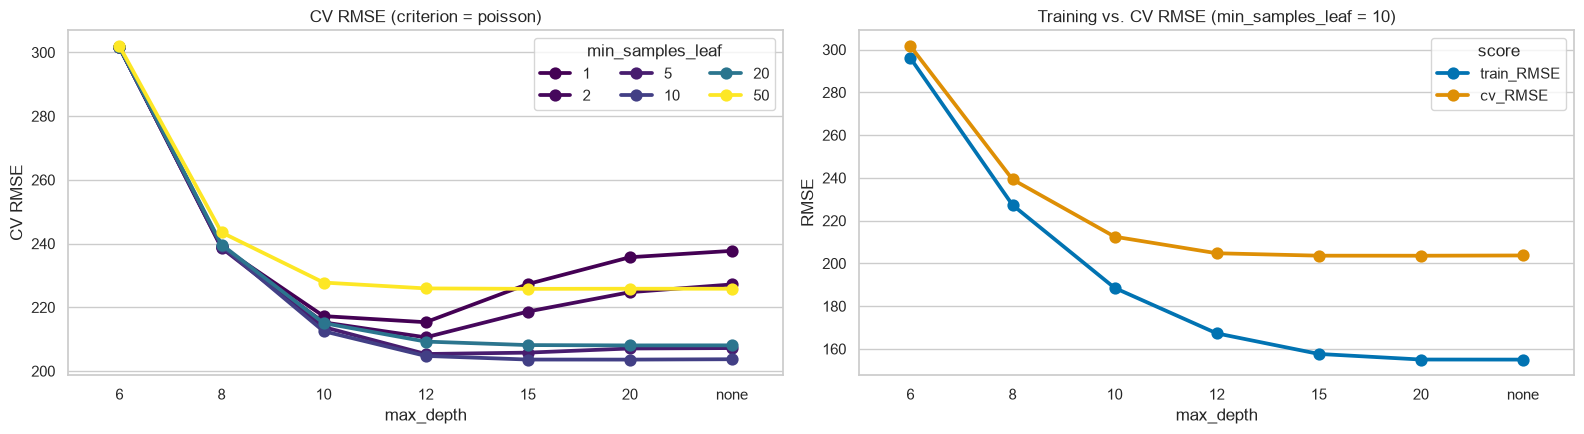

In [14]:
plot_data = tree_candidates.assign(max_depth=lambda d: d["max_depth"].astype(str))
depth_order = [str(label(d)) for d in tree_grid["model__max_depth"]]
best_params = short_params(tree_search.best_params_)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
best_criterion = plot_data[plot_data["criterion"] == best_params["criterion"]]
sns.pointplot(data=best_criterion, x="max_depth", y="cv_RMSE", hue="min_samples_leaf", order=depth_order,
              palette="viridis", ax=axes[0])
axes[0].set(title=f"CV RMSE (criterion = {best_params['criterion']})", ylabel="CV RMSE")
axes[0].legend(title="min_samples_leaf", ncols=3)

best_leaf = best_criterion[best_criterion["min_samples_leaf"] == best_params["min_samples_leaf"]]
gap = best_leaf.melt(id_vars="max_depth", value_vars=["train_RMSE", "cv_RMSE"], var_name="score", value_name="RMSE")
sns.pointplot(data=gap, x="max_depth", y="RMSE", hue="score", order=depth_order, ax=axes[1])
axes[1].set(title=f"Training vs. CV RMSE (min_samples_leaf = {best_params['min_samples_leaf']})")
plt.tight_layout()
plt.show()

In [15]:
tree_best = tree_search.best_estimator_  # refitted on the whole training set, kept for step 8
tree_best_scores = cv_scores(tree_best, "Decision tree (tuned)")
print("Best parameters:", short_params(tree_search.best_params_))
print("Depth:", tree_best["model"].get_depth(), "| leaves:", tree_best["model"].get_n_leaves())

14:14:54 | --- Decision tree (tuned) ---
14:14:54 | fold 1 | train RMSE  157.0 | val RMSE  199.0 | val MAE  125.8 | val R2 0.907 | fit 0.10 s
14:14:54 | fold 2 | train RMSE  156.3 | val RMSE  192.5 | val MAE  124.8 | val R2 0.912 | fit 0.07 s
14:14:54 | fold 3 | train RMSE  155.7 | val RMSE  198.4 | val MAE  126.9 | val R2 0.897 | fit 0.07 s
14:14:54 | fold 4 | train RMSE  154.8 | val RMSE  217.2 | val MAE  132.7 | val R2 0.882 | fit 0.07 s
14:14:54 | fold 5 | train RMSE  151.4 | val RMSE  210.8 | val MAE  128.8 | val R2 0.888 | fit 0.07 s
14:14:54 | mean   | train RMSE  155.0 | val RMSE  203.6 ± 9.0 | val MAE  127.8 | val R2 0.897
Best parameters: {'criterion': 'poisson', 'max_depth': 20, 'min_samples_leaf': 10}
Depth: 20 | leaves: 1081


**Findings (decision tree):**
- The **default tree** fits the training set perfectly (training RMSE 0: one leaf per hour) and overfits strongly, yet with a CV RMSE of ≈ 237 it is **already better than the tuned Ridge**. `max_depth=5` underfits (≈ 328).
- **`min_samples_leaf` matters more than `max_depth`:** with at least 10 hours per leaf, the tree hardly grows beyond depth 15 to 20, so `max_depth` = 15, 20 and none are within 0.1 RMSE. Leaves of 1 to 2 hours overfit, leaves of 50 hours underfit.
- **`poisson`** is a little better than `squared_error` for almost every tree size (≈ 203.6 vs. 206.3 for the best one).
- **Best tree:** `criterion=poisson`, `max_depth=20`, `min_samples_leaf=10` (≈ 1,100 leaves), CV RMSE ≈ 204, R² ≈ 0.90. The gap between training and CV RMSE (≈ 49) shows that it still overfits: that is the **variance** which random forests and boosting reduce in step 7.

## 5. Comparison of the best models

Both tuned models next to the baselines. All scores are means over the same 5 folds of the training set; the test set is still locked.

In [16]:
rule_rmse = baseline_scores.loc["Rule baseline (mean per hour)", "cv_RMSE"]
model_scores = pd.concat([baseline_scores, pd.DataFrame([ridge_best_scores, tree_best_scores])])
model_scores["RMSE_gap"] = model_scores["cv_RMSE"] - model_scores["train_RMSE"]  # overfitting
model_scores["vs_rule_baseline_%"] = 100 * (model_scores["cv_RMSE"] / rule_rmse - 1)
model_scores["best_params"] = pd.Series({
    "Ridge (tuned)": short_params(linear_search.best_params_),
    "Decision tree (tuned)": short_params(tree_search.best_params_),
})

columns = ["train_RMSE", "cv_RMSE", "cv_RMSE_std", "RMSE_gap", "vs_rule_baseline_%", "cv_MAE", "cv_R2", "fit_time_s", "best_params"]
model_scores[columns].round(3)

,train_RMSE,cv_RMSE,cv_RMSE_std,RMSE_gap,vs_rule_baseline_%,cv_MAE,cv_R2,fit_time_s,best_params
Mean baseline,636.223,636.227,11.995,0.003,61.097,522.059,-0.001,0.037,NaN
Rule baseline (mean per hour),393.568,394.934,6.326,1.366,0.000,279.195,0.614,0.026,NaN
Ridge (tuned),242.994,245.543,13.649,2.549,-37.827,155.033,0.850,0.082,"{'alpha': 0.01, 'target': 'log1p', 'hour': 'StandardScaler', 'interaction': 'OneHotEncoder'}"
Decision tree (tuned),155.035,203.592,9.044,48.556,-48.449,127.802,0.897,0.076,"{'criterion': 'poisson', 'max_depth': 20, 'min_samples_leaf': 10}"


**Which model handles the daily pattern better?** Out-of-fold predictions (`cross_val_predict`: every hour is predicted by the model that did not see it), averaged per hour of the day.

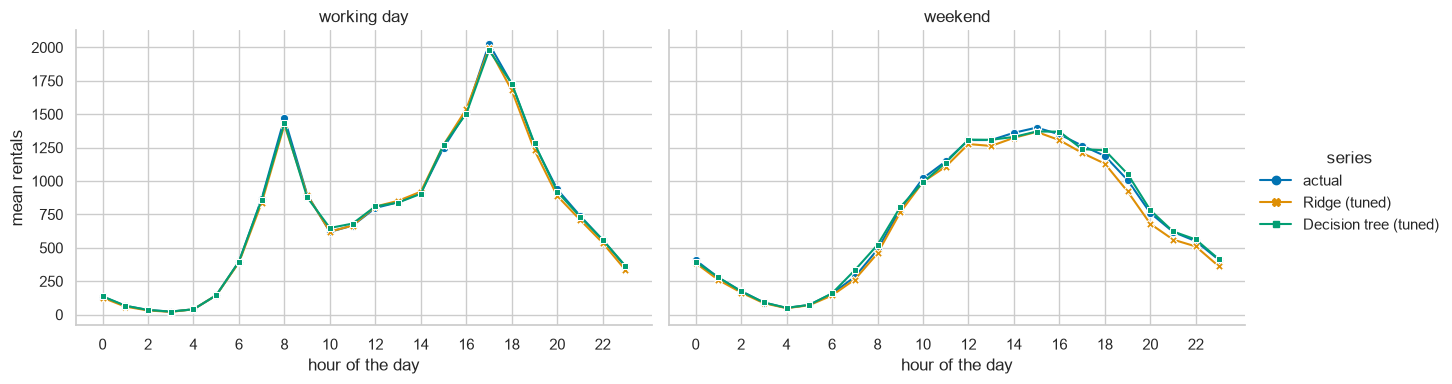

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
MAE by hour,,,,,,,,,,,,,,,,,,,,,,,,
Ridge (tuned),47,34,21,12,9,21,59,150,275,164,131,154,193,205,218,268,296,376,312,228,179,137,110,113
Decision tree (tuned),53,37,21,12,9,20,57,138,236,132,108,130,132,137,162,222,209,274,262,211,179,131,104,84


In [17]:
oof = df_train_prepared[["hour", "day_type", TARGET]].assign(
    **{
        "Ridge (tuned)": cross_val_predict(ridge_best, X_train, y_train, cv=cv),
        "Decision tree (tuned)": cross_val_predict(tree_best, X_train, y_train, cv=cv),
    }
).rename(columns={TARGET: "actual"})
oof["day_type"] = oof["day_type"].replace({"holiday": "weekend"})  # holidays are few and look like weekends

daily = oof.melt(id_vars=["hour", "day_type"], var_name="series", value_name="rentals")
grid = sns.relplot(data=daily, x="hour", y="rentals", hue="series", style="series", col="day_type", col_order=["working day", "weekend"], kind="line",
                   markers=True, dashes=False, errorbar=None, height=4, aspect=1.6)
grid.set_axis_labels("hour of the day", "mean rentals").set_titles("{col_name}")
grid.set(xticks=range(0, 24, 2))
plt.show()

errors = oof.assign(**{m: (oof[m] - oof["actual"]).abs() for m in ["Ridge (tuned)", "Decision tree (tuned)"]})
errors.groupby("hour")[["Ridge (tuned)", "Decision tree (tuned)"]].mean().round(0).astype(int).T.rename_axis("MAE by hour")

**Findings (comparison):**
- Both models beat the **rule baseline** clearly: CV RMSE −38 % (Ridge) and −48 % (tree).
- The **decision tree is better on every metric:** CV RMSE ≈ 204 vs. 246, MAE ≈ 128 vs. 155, R² ≈ 0.90 vs. 0.85.
- **Daily pattern:** *on average*, both reproduce the two commuter peaks and the weekend hump; the Ridge only thanks to the hand-made `hour` × `day_type` column, the tree learns it from the raw columns. The difference lies in the single hours: at the rush hours, the tree's errors are clearly smaller (MAE at 8:00 ≈ 236 vs. 275, at 17:00 ≈ 274 vs. 376). In the linear model, temperature, rain and season change every hour by the same factor; the tree can learn that rain at 17:00 on a working day costs far more rentals than rain at night.
- **Bias vs. variance:** the Ridge hardly overfits (gap ≈ 2.5) but cannot express all interactions; the tree is more flexible but overfits (gap ≈ 49).
- **Preprocessing:** the tree needs only ordinal codes for two text columns; the Ridge needs one-hot encoding, scaling, a hand-made interaction and a log target.
- Kept for step 8: `ridge_best`, `tree_best` (both refitted on the whole training set), `linear_search`, `tree_search`, `model_scores`.